# Experimental QUBO Allocation for IROPS

The objective is to develop the solver and measure feasible PNR/passenger allocation against the client’s external Gurobi reference. This experiment executes the supplied de-identified catalog. One-hot choices include unassignment; integer slack variables encode complete capacity constraints. The penalty exceeds a certified objective-range bound.

In [2]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'experiment.py').is_file())
sys.path.insert(0, str(ROOT))
from experiment import run_experiment, allocation_table
report = run_experiment(ROOT/'artifacts/notebook', progress=False)
print(allocation_table(report).to_string(index=False))
print('Client comparison:', report['client_comparison']['scope'])

Matplotlib is building the font cache; this may take a moment.


 seed  assigned_pnrs  assigned_passengers  pnr_allocation_percent  passenger_allocation_percent  capacity_violations  seconds
    7           4205                 5462                 54.9458                       46.2020                    0  19.8227
   11           4208                 5453                 54.9850                       46.1259                    0  19.7640
   29           4204                 5460                 54.9327                       46.1851                    0  19.6698
   47           4216                 5469                 55.0895                       46.2612                    0  19.6951
   73           4207                 5472                 54.9719                       46.2866                    0  19.7363
Client comparison: Client performs comparison independently; outside this solver


## Allocation validity

The denominator is the provided candidate-catalog population. Final assignments are independently rescored for indivisible parties and shared flight/cabin capacities. All fixed seeds are retained. Upstream journey/ranking anomalies remain explicit input limitations; client comparison requires matched rules and populations. Exact-rational capacity certificates independently bound the achievable allocation.

In [3]:
print('Catalog PNRs:', report['catalog']['pnrs'])
print('Catalog passengers:', report['catalog']['passengers'])
print(json.dumps(report['catalog']['input_audit'], indent=2))
print(json.dumps(report['summary'], indent=2))
print('Capacity upper bounds:', json.dumps(report['capacity_upper_bounds'], indent=2))
print('End-to-end runtime (all seeds):', round(report['timing']['end_to_end_seconds'], 3), 'seconds')

Catalog PNRs: 7653
Catalog passengers: 11822
{
  "capacity_policy": "conservative",
  "negative_capacities_clipped": 622,
  "capacity_conflicts_resolved": 0,
  "cvm_source": "CVM",
  "departure_source": "candidates",
  "options_with_original_duration_over_72h": 33533,
  "options_arriving_over_72h_before_original": 28330,
  "ranking_boundary": "Supplied normalized features are preserved; original-journey segmentation and feature quality are external to this solver"
}
{
  "pnr_allocation_percent": {
    "mean": 54.984973213119034,
    "sample_std": 0.061981137988404246,
    "minimum": 54.932706128315694,
    "maximum": 55.08950738272573
  },
  "passenger_allocation_percent": {
    "mean": 46.2121468448655,
    "sample_std": 0.06369430078503165,
    "minimum": 46.12586702757571,
    "maximum": 46.286584334291994
  },
  "assigned_pnrs": {
    "mean": 4208.0,
    "sample_std": 4.743416490252569,
    "minimum": 4204.0,
    "maximum": 4216.0
  },
  "seconds": {
    "mean": 19.7375849081669,
 

## Execution and logical resources

This is classical simulated annealing with whole-PNR decomposition and reconciliation. Raw sample diagnostics and repaired outcomes are separate. Couplers, slack overhead and coefficient ranges expose encoding costs; they do not establish hardware feasibility or quantum advantage. See the concise [README](README.md).

 seed  chunks  peak_variables  peak_couplers  maximum_ising_dynamic_range  raw_zero_residual_samples  total_samples  summed_raw_chunk_overloads
    7     320             128           1170                317741.743950                      13900          15360                           0
   11     322             128           1282                273038.294680                      13953          15456                           0
   29     320             128           1109                278635.321354                      13974          15360                           0
   47     320             128           1009                289720.596747                      13896          15360                           0
   73     322             128           1101                273038.294680                      13918          15456                           0


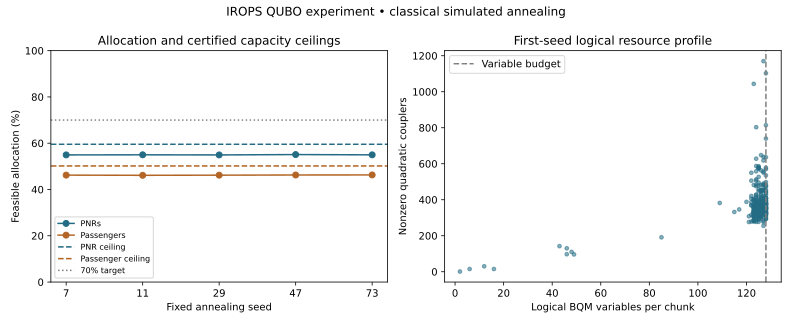

In [4]:
import pandas as pd
resource_rows = [{'seed': r['seed'], **r['resources']} for r in report['runs']]
print(pd.DataFrame(resource_rows).to_string(index=False))
from IPython.display import SVG, display
display(SVG(filename=str(ROOT/'artifacts/notebook/allocation_resources.svg')))